In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
df=pd.read_csv(r"C:\Users\bisha\Downloads\TSLA\TSLA.csv")
df.head(5)

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500


In [3]:
#Checking for the missing values and basic statistical information
miss=df.isnull().sum()
stats=df.describe()
miss,stats

(Date         0
 Open         0
 High         0
 Low          0
 Close        0
 Adj Close    0
 Volume       0
 dtype: int64,
               Open         High          Low        Close    Adj Close  \
 count  2956.000000  2956.000000  2956.000000  2956.000000  2956.000000   
 mean    138.691296   141.771603   135.425953   138.762183   138.762183   
 std     250.044839   255.863239   243.774157   250.123115   250.123115   
 min       3.228000     3.326000     2.996000     3.160000     3.160000   
 25%      19.627000    20.402000    19.127500    19.615000    19.615000   
 50%      46.656999    47.487001    45.820002    46.545000    46.545000   
 75%      68.057001    69.357500    66.911501    68.103998    68.103998   
 max    1234.410034  1243.489990  1217.000000  1229.910034  1229.910034   
 
              Volume  
 count  2.956000e+03  
 mean   3.131449e+07  
 std    2.798383e+07  
 min    5.925000e+05  
 25%    1.310288e+07  
 50%    2.488680e+07  
 75%    3.973875e+07  
 max    3.04

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2956 entries, 0 to 2955
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2956 non-null   object 
 1   Open       2956 non-null   float64
 2   High       2956 non-null   float64
 3   Low        2956 non-null   float64
 4   Close      2956 non-null   float64
 5   Adj Close  2956 non-null   float64
 6   Volume     2956 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 161.8+ KB


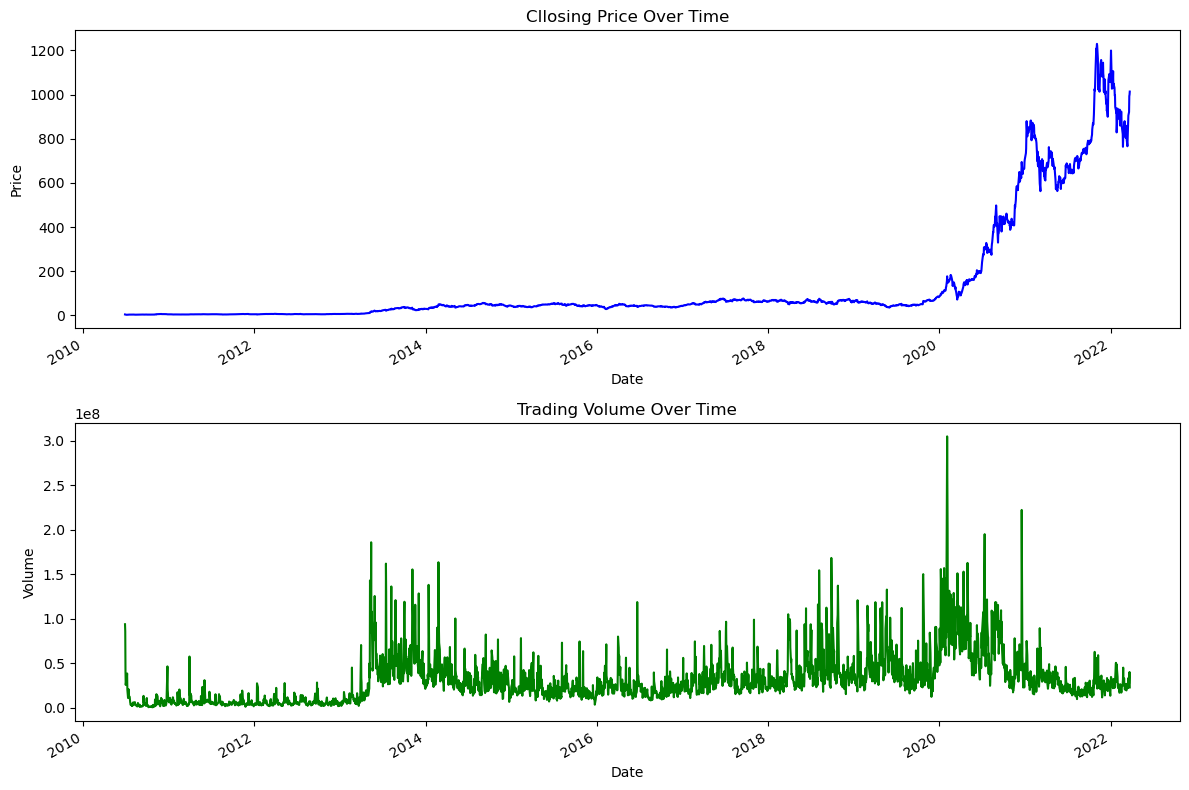

In [5]:
df['Date']=pd.to_datetime(df['Date'])
#Set the date as the index of dataframe for plotting
df.set_index('Date',inplace=True)

#create a figure and set of subplots
fig,ax=plt.subplots(2,1,figsize=(12,8))

df['Close'].plot(ax=ax[0],color='blue')
ax[0].set_title('Cllosing Price Over Time')
ax[0].set_ylabel('Price')

df['Volume'].plot(ax=ax[1],color='green')
ax[1].set_title('Trading Volume Over Time')
ax[1].set_ylabel('Volume')

plt.tight_layout()
plt.show()

<Figure size 1300x900 with 0 Axes>

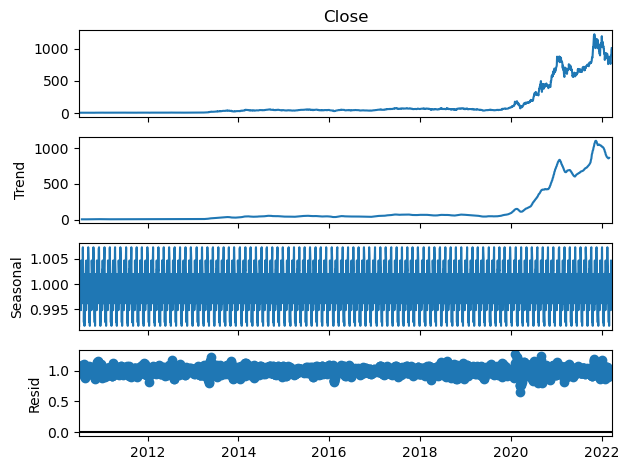

In [6]:
decomposition=seasonal_decompose(df['Close'],model='multiplicative',period=30)
plt.figure(figsize=(13,9))
fig=decomposition.plot()
plt.show()

The Seasonal decomposition of the closing prices of Tesla's stock reveals the following:
- Trend:The Trend component shows a general upwaard trend in Tesla's price over the year.Graph indicates the long-term movement of Tesla's price is upwards.
- seasonal:Some minor fluctuations suggest some recurring patterns that might be on monthly basis.
- Residual: The residuals (the variation in the stock price not explained by the trend and seasonality)appear to increase over time shows the unpredictibility in data.
- Now we have to perform volality analysis for measuring fluctation due to different factors.

In [7]:
#Arch test for volatility testing
from statsmodels.stats.diagnostic import het_arch
df['return']=df['Close'].pct_change()
arch_test_result = het_arch(df['return'].dropna())
print("ARCH Test Statistic:", arch_test_result[0])
print("p-value:", arch_test_result[1])
print("Lags used:", arch_test_result[2])


ARCH Test Statistic: 152.4970508913809
p-value: 1.1415101781556161e-27
Lags used: 16.022412705352096


The p-value<<0.05 so we reject null hypothesis that volatility is constant.

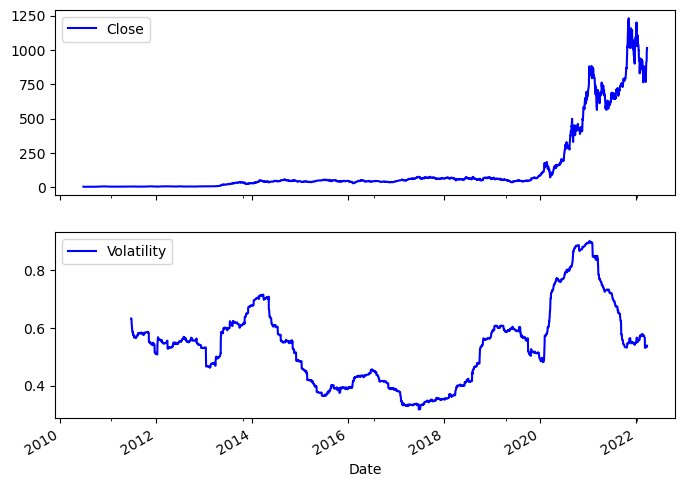

In [8]:
#Volality Analysis
df['Volatility']=df['return'].rolling(window=252).std()*np.sqrt(252)
df[['Close','Volatility']].plot(subplots=True,color='blue',figsize=(8,6))
plt.show()

Also wee see by the graph that there is several spikes which shows that there are some periods when the returns change dramatically, indicating high risk or uncertainity during those periods.

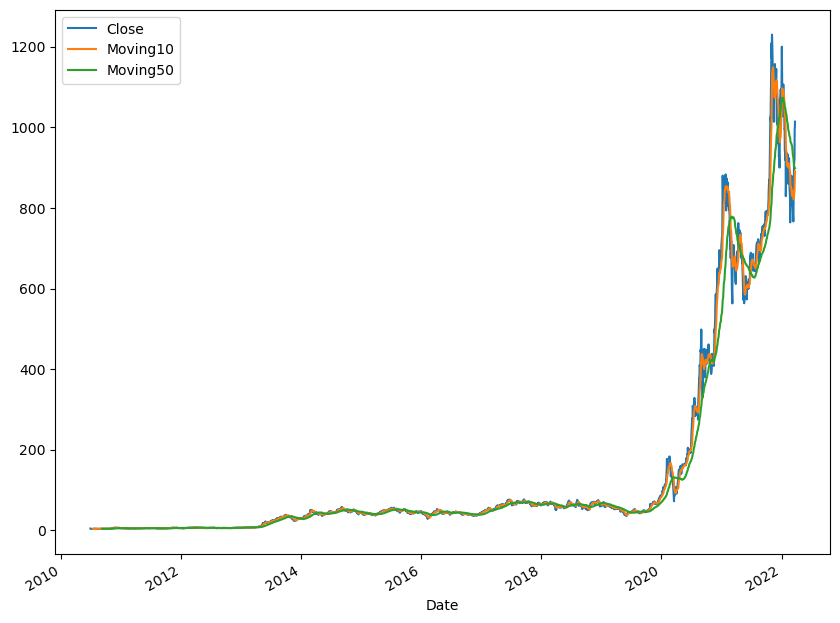

In [9]:
#Moving Average Analysis
df['Moving10']=df['Close'].rolling(window=10).mean()
df['Moving50']=df['Close'].rolling(window=50).mean()
df[['Close','Moving10','Moving50']].plot(label='Tesla',figsize=(10,8))
plt.show()

One common strategy used by some traders is to look for crossing of different moving averages signal for buying and selling opportunities.For example if Moving10 croses Moving50 it means there is a buying chances,Conversly,when Moving10 crosses below Moving50 ,it could be sell signal.

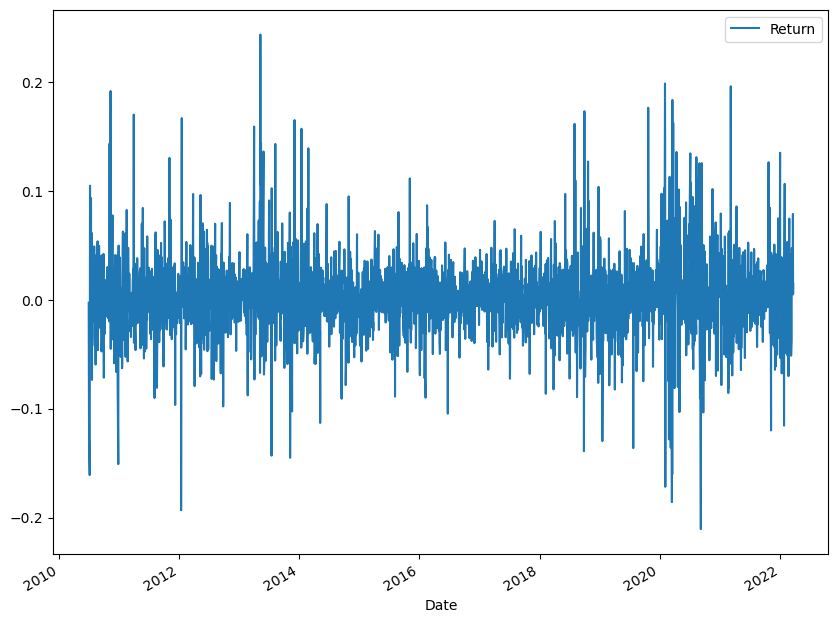

In [10]:
#Return Analysis
df['Return']=df['Close'].pct_change()
df[['Return']].plot(label='Return',figsize=(10,8))
plt.show()

The return analysis chart illustrates the daily percentage change in tesla's stock price:
- The daily return fluctuates around 0,mix of positives and negative returns. This indicates that the stock prices has direction of both gains and losses.
- The magnitude of daily return provides some indication of the stock's volatility. Larger swings (both up and down) indicate more volatility as seen in the chart, there are periods with higher volatility (larger fluctuations in returns) and periods with lower volatility

### Model Building

In [11]:
# Initialize the Prophet model
from prophet import Prophet
model=Prophet(daily_seasonality=True)


In [12]:

prophet_df=df.reset_index()[['Date','Close']]

prophet_df.rename(columns={'Date':'ds','Close':'y'},inplace=True)

prophet_df.head()

,ds,y
0,2010-06-29,4.778
1,2010-06-30,4.766
2,2010-07-01,4.392
3,2010-07-02,3.840
4,2010-07-06,3.222


In [13]:
prophet_df.isnull().sum()

ds    0
y     0
dtype: int64

In [14]:
model.fit(prophet_df)

17:03:13 - cmdstanpy - INFO - Chain [1] start processing
17:03:13 - cmdstanpy - INFO - Chain [1] done processing


In [15]:
#Specify the number of days for predictions
future=model.make_future_dataframe(periods=365)

#Use the model to make predictions
forecast = model.predict(future)

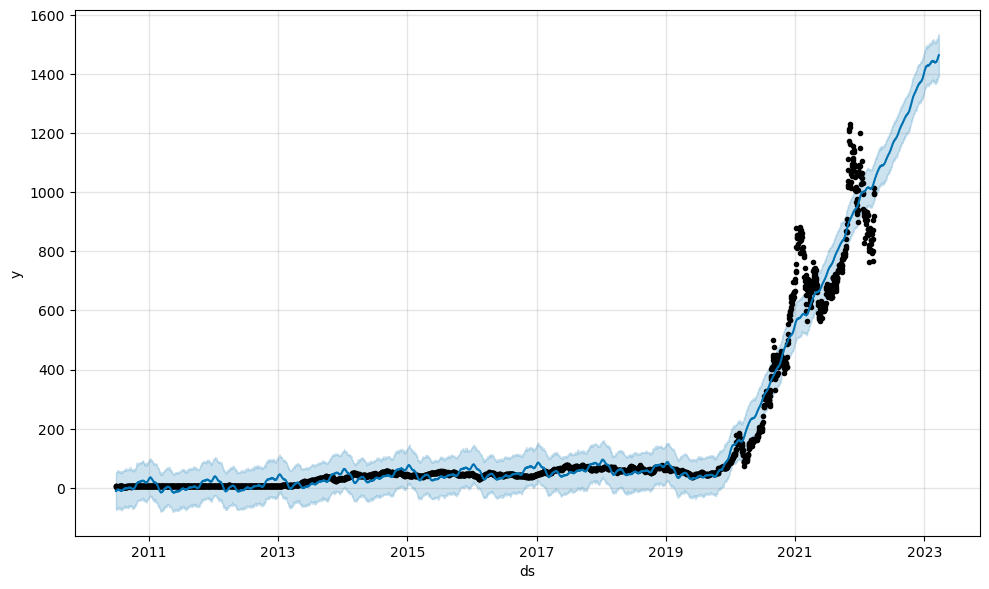

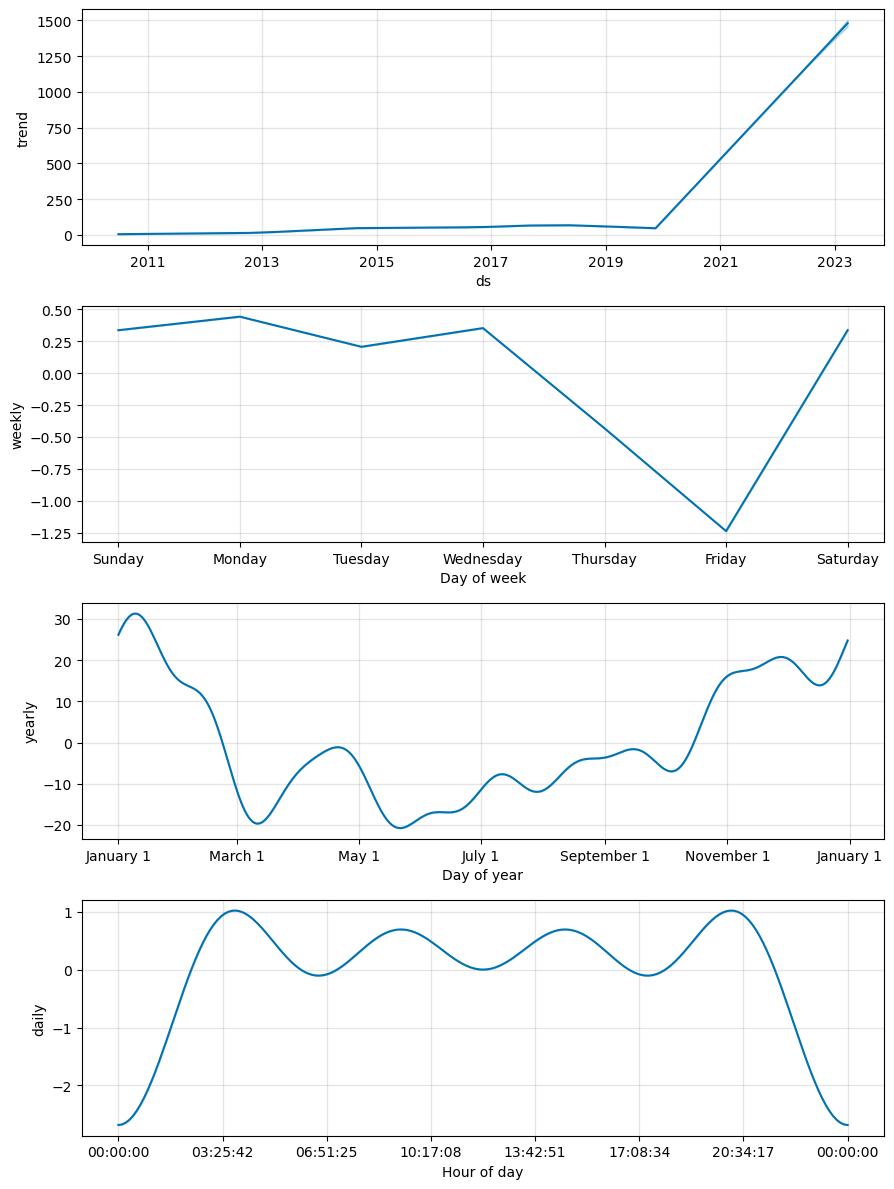

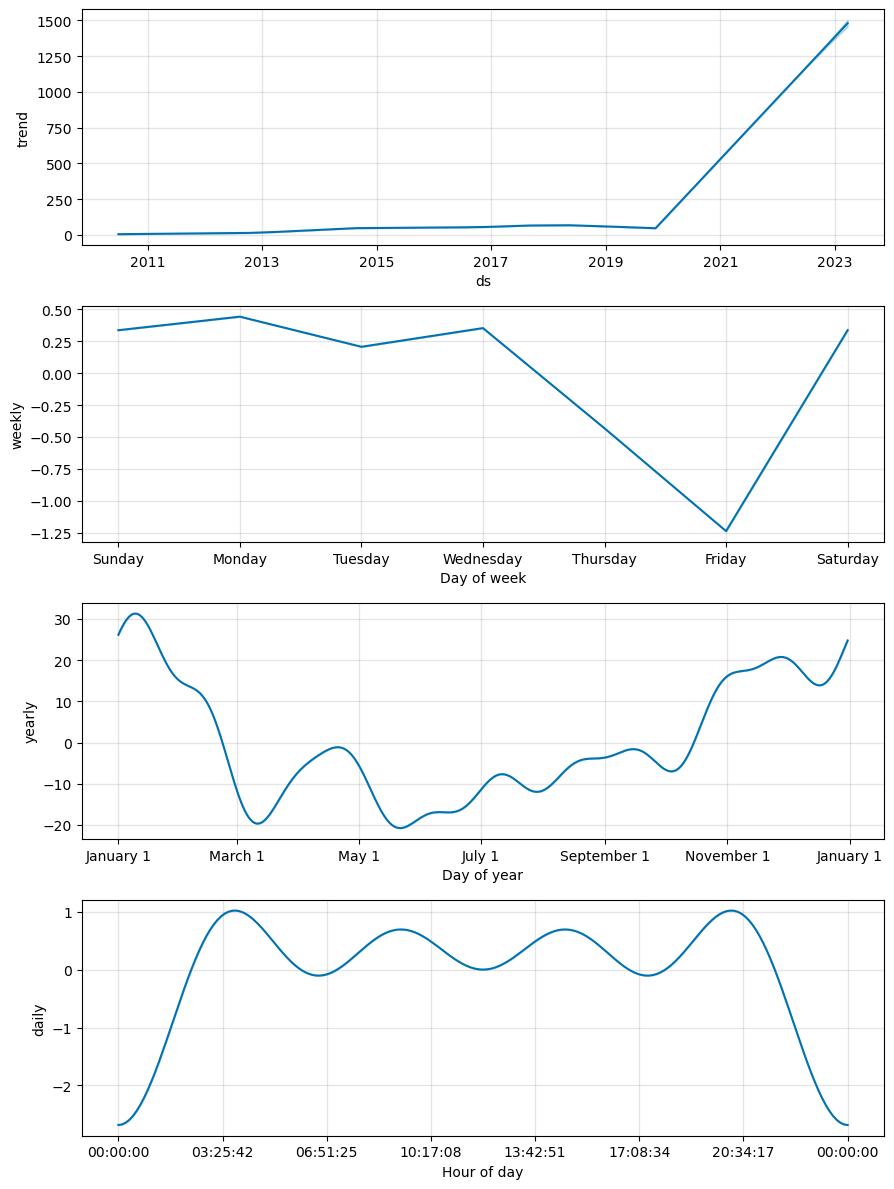

In [16]:
model.plot(forecast)
plt.show()

#Components of the model
model.plot_components(forecast)